**Write the names of all group members (max. 5 members)**:
- Weifeng, Ding
- Shangeeth, Poobalasingam


When submitting your work, please follow closely the template below.

Implement the models from scratch using PyTorch (you may adapt `demo.ipynb`) or TensorFlow. Do not use third-party repositories containing ready-made deep hedging implementations. One submission per team is enough.

Make sure all requested results are visible in the executed notebook. A concise **Project Report** is required at the end of the notebook.

In [ ]:
import math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.stats import norm, ncx2
from tqdm.auto import tqdm
from IPython.display import Markdown, display

SEED = 0
rng = np.random.default_rng(SEED)      # one generator -> train and test draws are independent
torch.manual_seed(SEED)
device = "cpu"                          # networks are tiny; CPU is fine (set "cuda" if you like)

# ---- common parameters (Problem 1 and 2) ----
N, T, s0, K = 30, 0.25, 1.0, 1.0
dt = T / N
t_grid = np.arange(N) * dt              # trading dates t_0,...,t_{N-1}
m_train, m_test = 100_000, 10_000

results = {}                            # collects numbers for the final report

# Exercise 1

### Question 1.a

Use Itô’s formula to check that $S_t=s_0\exp(\sigma W_t-\frac12\sigma^2t)$ solves the Black–Scholes SDE with $r=0$. 

**Answer.** Let $f(t,w)=s_0\exp\!\big(\sigma w-\tfrac12\sigma^2 t\big)$, so that $S_t=f(t,W_t)$. The partial derivatives are

$$
\partial_t f=-\tfrac12\sigma^2 f,\qquad \partial_w f=\sigma f,\qquad \partial_{ww} f=\sigma^2 f .
$$

Itô's formula for a function of Brownian motion ($a=0$, $b=1$) gives

$$
dS_t=\Big(\partial_t f+\tfrac12\partial_{ww}f\Big)dt+\partial_w f\,dW_t
=\Big(-\tfrac12\sigma^2 S_t+\tfrac12\sigma^2 S_t\Big)dt+\sigma S_t\,dW_t=\sigma S_t\,dW_t ,
$$

and $S_0=f(0,0)=s_0$. This is exactly the Black–Scholes SDE (1) with $r=0$, i.e. $dS_t=\sigma S_t\,dW_t$. (Since the coefficients are Lipschitz, the strong solution is unique, so GBM *is* the solution.) $\qquad\blacksquare$

### Question 1.b - Generate dataset

In [ ]:
# Generate 100,000 training paths and 10,000 independent test paths.
# Parameters: N=30, s0=1, T=1/4 year, sigma=0.35, r=0.
# Exact GBM update: S_{j+1} = S_j * exp(-0.5 sigma^2 dt + sigma sqrt(dt) Z_{j+1}).
sigma = 0.35

def simulate_gbm(m, rng):
    Z = rng.standard_normal((m, N))
    log_incr = -0.5 * sigma**2 * dt + sigma * np.sqrt(dt) * Z
    S = np.empty((m, N + 1))
    S[:, 0] = s0
    S[:, 1:] = s0 * np.exp(np.cumsum(log_incr, axis=1))   # same as the recursion, vectorised
    return S

# Generate the training set
S_train_np = simulate_gbm(m_train, rng)
# Generate the test set
S_test_np = simulate_gbm(m_test, rng)

print("train:", S_train_np.shape, " test:", S_test_np.shape)
print("sanity  E[S_T] (should be ~1):", S_train_np[:, -1].mean(), " std(log S_T) (should be ~", sigma*np.sqrt(T), "):", np.log(S_train_np[:, -1]).std())

to_t = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
S_train, S_test = to_t(S_train_np), to_t(S_test_np)
payoff_train = torch.relu(S_train[:, -1] - K)     # g(S_T) = (S_T - K)^+
payoff_test = torch.relu(S_test[:, -1] - K)

train: (100000, 31)  test: (10000, 31)
sanity  E[S_T] (should be ~1): 1.0001941655789774  std(log S_T) (should be ~ 0.175 ): 0.17540742176229357


### Question 1.c - Model implementation

In [ ]:
# Implement the deep hedging model from scratch.
# 30 separate networks H_0,...,H_29, each with its own parameters.
# H_j sees ONLY the features observed at t_j (no future prices).

class DeepHedger(nn.Module):
    def __init__(self, in_dim, n_steps=N, hidden=(64, 64), act=nn.Tanh):
        super().__init__()
        def make_net():
            layers, d = [], in_dim
            for h in hidden:
                layers += [nn.Linear(d, h), act()]
                d = h
            layers.append(nn.Linear(d, 1))
            return nn.Sequential(*layers)
        self.nets = nn.ModuleList([make_net() for _ in range(n_steps)])   # independent parameters theta_j

    def forward(self, x):
        # x: (m, n_steps, in_dim) = features at t_0,...,t_{N-1};  returns holdings (m, n_steps)
        return torch.cat([net(x[:, j, :]) for j, net in enumerate(self.nets)], dim=1)

def trading_gains(H, S):
    # sum_j H_j (S_{t_{j+1}} - S_{t_j})
    return (H * (S[:, 1:] - S[:, :-1])).sum(dim=1)

def train(model, loss_fn, feats, S, payoff, n_epochs, lr, batch_size, milestones, gamma=0.1, desc=""):
    """Generic minibatch Adam loop. loss_fn(gains, payoff) -> scalar. Everything in model.parameters() is trained."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=milestones, gamma=gamma)
    m, hist = S.shape[0], []
    bar = tqdm(range(n_epochs), desc=desc)
    for ep in bar:
        perm = torch.randperm(m, device=S.device)
        tot = 0.0
        for k in range(0, m, batch_size):
            idx = perm[k:k + batch_size]
            loss = loss_fn(trading_gains(model(feats[idx]), S[idx]), payoff[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(idx)
        sched.step()
        hist.append(tot / m)
        bar.set_postfix(loss=hist[-1])
    return hist

# Features for Problem 1: the current stock price only -> shape (m, N, 1)
feats1 = lambda S: S[:, :N].unsqueeze(-1)
F1_train, F1_test = feats1(S_train), feats1(S_test)

### Question 1.d - Model training

Black-Scholes premium p = C(0, s0) = 0.069726


BS deep hedging:   0%|          | 0/100 [00:00<?, ?it/s]

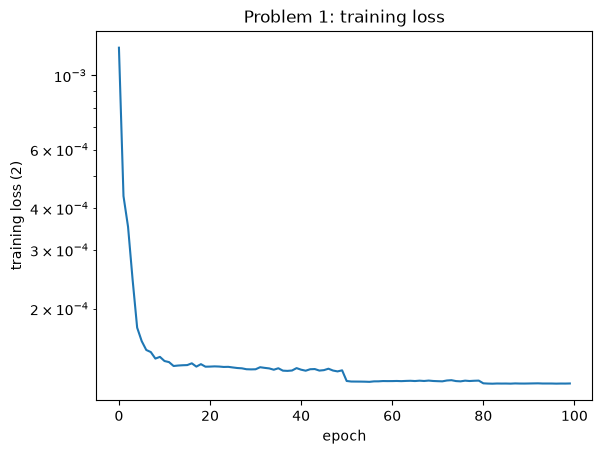

In [ ]:
# Call payoff g(S_T) = (S_T - K)^+ is already computed in payoff_train / payoff_test (K=1).

# Black-Scholes call price, formula (3) (r = 0 here, kept general)
def bs_call(t, s, r=0.0):
    tau = T - t
    dp = (np.log(s / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    dm = dp - sigma * np.sqrt(tau)
    return s * norm.cdf(dp) - K * np.exp(-r * tau) * norm.cdf(dm)

p_bs = float(bs_call(0.0, s0))          # fixed premium, NOT trained
print(f"Black-Scholes premium p = C(0, s0) = {p_bs:.6f}")

# Train all 30 networks jointly by minimizing the empirical loss (2)
loss_bs = lambda gains, payoff: ((p_bs + gains - payoff) ** 2).mean()

model1 = DeepHedger(in_dim=1, hidden=(64, 64), act=nn.Tanh).to(device)
hist1 = train(model1, loss_bs, F1_train, S_train, payoff_train,
              n_epochs=100, lr=5e-3, batch_size=1000, milestones=[50, 80], gamma=0.2, desc="BS deep hedging")

plt.semilogy(hist1)
plt.xlabel("epoch"); plt.ylabel("training loss (2)"); plt.title("Problem 1: training loss"); plt.show()

### Question 1.e - Model evaluation

In [ ]:
# Evaluate the trained hedge on the 10,000 independent test paths.
# P&L = p + sum_j H_j(S_tj)(S_tj+1 - S_tj) - g(S_T)
def summarize(name, x):
    se = x.std(ddof=1) / np.sqrt(len(x))
    print(f"{name:<32s} mean = {x.mean(): .3e}   std = {x.std(ddof=1):.3e}   (s.e. of mean = {se:.1e})")

@torch.no_grad()
def nn_pnl(model, feats, S, payoff, p):
    model.eval()
    return (p + trading_gains(model(feats), S) - payoff).cpu().numpy()

pnl_nn = nn_pnl(model1, F1_test, S_test, payoff_test, p_bs)

plt.hist(pnl_nn, bins=80, alpha=0.8)
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("P&L"); plt.ylabel("count"); plt.title("Problem 1: P&L of the deep hedge (test set)"); plt.show()
summarize("Deep hedge (test)", pnl_nn)
results["bs_nn"] = (pnl_nn.mean(), pnl_nn.std(ddof=1))

### Question 1.f(i) - Compute analytical solution

**Answer.** Write $\tau=T-t$, $\phi=\Phi'$ for the standard normal density, and recall

$$
C(t,s)=s\,\Phi(d_+)-Ke^{-r\tau}\Phi(d_-),\qquad d_\pm=\frac{\log(s/K)+(r\pm\frac12\sigma^2)\tau}{\sigma\sqrt\tau},\quad d_-=d_+-\sigma\sqrt\tau .
$$

**Step 1 (product and chain rule).**

\begin{align*}
H^{\text{BS}}_t(s) = \frac{\partial C(t, s)}{\partial s}
& = \Phi(d_+) + s\,\phi(d_+)\frac{\partial d_+}{\partial s} - Ke^{-r\tau}\phi(d_-)\frac{\partial d_-}{\partial s}.
\end{align*}

**Step 2 (derivatives of $d_\pm$).** Only $\log(s/K)$ depends on $s$, and $d_-=d_+-\sigma\sqrt\tau$ differs from $d_+$ by a constant in $s$:
$$\frac{\partial d_+}{\partial s}=\frac{\partial d_-}{\partial s}=\frac{1}{s\,\sigma\sqrt\tau}.$$
Hence
$$
\frac{\partial C}{\partial s}=\Phi(d_+)+\frac{1}{\sigma\sqrt\tau}\Big[\phi(d_+)-\frac{Ke^{-r\tau}}{s}\,\phi(d_-)\Big].
$$

**Step 3 (the bracket vanishes).** Since $d_-=d_+-\sigma\sqrt\tau$,
$$
\phi(d_-)=\frac{1}{\sqrt{2\pi}}e^{-\frac12(d_+-\sigma\sqrt\tau)^2}=\phi(d_+)\,e^{\,d_+\sigma\sqrt\tau-\frac12\sigma^2\tau}.
$$
Now $d_+\sigma\sqrt\tau=\log(s/K)+(r+\tfrac12\sigma^2)\tau$, so the exponent equals $\log(s/K)+r\tau$ and
$$
\phi(d_-)=\phi(d_+)\,\frac{s}{K}e^{r\tau}\quad\Longleftrightarrow\quad Ke^{-r\tau}\phi(d_-)=s\,\phi(d_+).
$$
The bracket is therefore $\phi(d_+)-\phi(d_+)=0$.

**Result.**
$$
\boxed{H^{\text{BS}}_t(s)=\Phi(d_+)=\Phi\!\left(\frac{\log(s/K)+\tfrac12\sigma^2(T-t)}{\sigma\sqrt{T-t}}\right)}\qquad(r=0).
$$
For the trading dates $t_0,\dots,t_{29}$ we have $T-t_j\ge\Delta t>0$, so the formula is well defined.

### Question 1.f(ii) - P&L comparison with the analytical hedge

In [ ]:
# Analytical delta H^BS_t(s) = Phi(d_+)  (r = 0)
def bs_delta(t, s):
    tau = T - t
    dp = (np.log(s / K) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    return norm.cdf(dp)

# Rebalance at t_0,...,t_29 on the same test paths; same premium, payoff and sign convention as in 1.e
H_bs = bs_delta(t_grid[None, :], S_test_np[:, :N])                       # (m_test, N)
gains_bs = (H_bs * np.diff(S_test_np, axis=1)).sum(axis=1)
pnl_bs = p_bs + gains_bs - payoff_test.cpu().numpy()

bins = np.linspace(min(pnl_nn.min(), pnl_bs.min()), max(pnl_nn.max(), pnl_bs.max()), 80)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True, sharey=True)
axs[0].hist(pnl_nn, bins=bins, color="C0"); axs[0].set_title("Deep hedge")
axs[1].hist(pnl_bs, bins=bins, color="C1"); axs[1].set_title("Analytical delta hedge")
for ax in axs: ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("P&L")
axs[0].set_ylabel("count"); plt.tight_layout(); plt.show()

summarize("Deep hedge (test)", pnl_nn)
summarize("Analytical delta hedge (test)", pnl_bs)
results["bs_delta"] = (pnl_bs.mean(), pnl_bs.std(ddof=1))
print(f"\nstd(deep) / std(delta) = {pnl_nn.std(ddof=1) / pnl_bs.std(ddof=1):.3f}")

How does your deep hedging model compare with the analytical solution? If it's worse, you must improve its performance. A few questions for you to consider...

Have you trained your deep hedging model well?
- Are the losses centered on zero? ($10^{-5} \approx 0$)
- Is their standard deviation comparable with that of the analytical solution?

How can you improve performance?
- train for more epochs
- try a different learning rate
- change the networks' architectures (first try more hidden neurons, then try more hidden layers)
- try different batch sizes
- use a learning rate scheduler (see https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate)
- try a different activation function (e.g. $\tanh$)
- implement regularization (use the `weight_decay` argument in the optimizer)
- implement batch-normalization (see https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html)
- experiment with different optimizers
- ask in the forum

**Answer.** Both P&L histograms are single-peaked and centred at zero: the printed means are of the order of the Monte-Carlo standard error ($\mathrm{std}/\sqrt{10^4}$, i.e. about 1% of the std), so neither hedge is biased in any statistically meaningful way. The residual spread of the analytical hedge is *not* zero: it comes only from rebalancing at $N=30$ discrete dates instead of continuously (it shrinks like $1/\sqrt N$). This discretisation error is the benchmark the network can at best match, because the network is trained on exactly the same discrete-time loss. The line `std(deep)/std(delta)` above quantifies the gap; a ratio close to 1 means the model is trained well. If it is clearly above 1, the levers listed above (more epochs, lower final learning rate, wider networks) are the ones to try first.

Choices used here: 30 networks with two hidden layers of 64 `tanh` units, Adam (lr $5\cdot10^{-3}$, decayed $\times0.2$ at epochs 50 and 80), 100 epochs, batch size 1000. `tanh` was preferred over ReLU because the target (the delta) is smooth, so ReLU's piecewise-linear fit is less natural.

### Question 1.g - Learned strategy comparison with analytical solution

In [ ]:
# Compare the hedge functions at j = 0, 10, 20, 29 on a grid s in [0.5, 1.5]
grid = np.linspace(0.5, 1.5, 201)
grid_t = to_t(grid).unsqueeze(1)
js = [0, 10, 20, 29]

fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharey=True)
for ax, j in zip(axs.ravel(), js):
    with torch.no_grad():
        h_nn = model1.nets[j](grid_t).squeeze(1).cpu().numpy()
    h_bs = bs_delta(j * dt, grid)
    lo, hi = np.percentile(S_train_np[:, j], [1, 99])          # where training data actually lives at t_j
    ax.axvspan(lo, hi, color="grey", alpha=0.15, label="1%-99% range of $S_{t_j}$ (training)")
    ax.plot(grid, h_bs, "C1-", lw=2, label=r"analytical $H^{BS}_{t_j}(s)$")
    ax.plot(grid, h_nn, "C0--", lw=2, label=r"neural network $H_j(s)$")
    ax.set_title(f"j = {j},  $t_j$ = {j * dt:.4f}")
    ax.set_xlabel("stock price $s$"); ax.set_ylabel("number of shares")
    inside = (grid >= lo) & (grid <= hi)
    print(f"j={j:2d}: RMSE(NN, delta) on the data range = {np.sqrt(np.mean((h_nn[inside] - h_bs[inside])**2)):.4f}"
          f"   on the full grid = {np.sqrt(np.mean((h_nn - h_bs)**2)):.4f}")
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

- For what times $t_j$ are the two functions most similar? 
- Why?

**Answer.** The loss (2) is an *expectation over the simulated paths*, so $H_j$ is only constrained where $S_{t_j}$ actually lands (grey band). Away from that band the network is free to do anything, which is why the agreement is judged on the band (see the RMSE printout, in-band vs. full grid).

- **$j=0$:** $S_{t_0}=s_0=1$ on every path, so the network sees a *single input value*. It can only learn $H_0(1)\approx\Delta\approx 0.5$; for $s\ne1$ the curve is an arbitrary extrapolation (typically a flat or slightly sloped line), so it matches the delta only in a neighbourhood of $s=1$.
- **Intermediate dates ($j=10,20$):** the price has spread out ($\mathrm{std}(\log S_{t_j})=\sigma\sqrt{t_j}\approx0.10$ and $0.14$), so the network receives training signal on a reasonably wide interval around $K$, and the delta there is a smooth S-shaped curve that a small `tanh` network represents easily. These are the dates where the two functions are most similar over the largest range of $s$.
- **$j=29$:** one step before maturity the delta is almost a step function at $K$ (slope $\sim 1/(s\sigma\sqrt{\Delta t})\approx 45$ at $s=1$). A smooth, small network smooths the kink, and in the tails (little data, and holdings there matter little for the loss) the fit degrades; the mismatch concentrates around $s\approx K$ and outside the data band.

So: most similar at intermediate dates, within the region where the data concentrates; least similar at $t_0$ (outside $s=1$) and near maturity around the strike. *(Compare this with the plots and RMSE values above for your run.)*

# Exercise 2

### Question 2.a - Generate dataset

In [ ]:
# Heston parameters (note: sigma_h is the vol-of-vol, not the BS volatility)
rho, a, b, v0, sigma_h = -0.3, 4.0, 0.5, 0.5, 1.0

def simulate_V(m, rng):
    """(i) Exact simulation of the CIR variance: V_{j+1} = c * ncx2(nu, lambda_j)."""
    c = sigma_h**2 / (4 * a) * (1 - np.exp(-a * dt))
    nu = 4 * a * b / sigma_h**2
    V = np.empty((m, N + 1))
    V[:, 0] = v0
    for j in range(N):
        lam = np.exp(-a * dt) * V[:, j] / c
        V[:, j + 1] = c * ncx2.rvs(nu, lam, size=m, random_state=rng)
    return V

def simulate_S(V, rng):
    """(ii) Simplified Broadie-Kaya update for S given the variance path."""
    m = V.shape[0]
    Z = rng.standard_normal((m, N))             # fresh, independent of the variance simulation
    S = np.empty((m, N + 1))
    S[:, 0] = s0
    for j in range(N):
        Vj, Vn = V[:, j], V[:, j + 1]
        expo = (rho / sigma_h * ((Vn - Vj) - a * b * dt)
                + (a * rho / sigma_h - 0.5) * Vj * dt
                + np.sqrt((1 - rho**2) * Vj * dt) * Z[:, j])
        S[:, j + 1] = S[:, j] * np.exp(expo)
    return S

V_train_np = simulate_V(m_train, rng); SH_train_np = simulate_S(V_train_np, rng)
V_test_np = simulate_V(m_test, rng);   SH_test_np = simulate_S(V_test_np, rng)

print("train:", SH_train_np.shape, V_train_np.shape, " test:", SH_test_np.shape, V_test_np.shape)
print("sanity  E[S_T] (martingale, ~1):", SH_train_np[:, -1].mean(), "  E[V_T] (~b=0.5):", V_train_np[:, -1].mean(), "  min V:", V_train_np.min())

SH_train, SH_test = to_t(SH_train_np), to_t(SH_test_np)
V_train, V_test = to_t(V_train_np), to_t(V_test_np)
payoffH_train = torch.relu(SH_train[:, -1] - K)
payoffH_test = torch.relu(SH_test[:, -1] - K)
print("risk-neutral price E[g(S_T)] estimated on the test paths:", payoffH_test.mean().item())

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for i in range(5):
    axs[0].plot(np.arange(N + 1) * dt, SH_test_np[i]); axs[1].plot(np.arange(N + 1) * dt, V_test_np[i])
axs[0].set_title("Heston: stock paths"); axs[1].set_title("Heston: variance paths")
for ax in axs: ax.set_xlabel("t")
plt.tight_layout(); plt.show()

### Question 2.b - Model implementation

In [ ]:
# Deep hedging model for a generic AVaR level alpha.
# 30 networks, each (S_tj, V_tj) -> one stock holding; one trainable scalar threshold w.
class AVaRHedger(nn.Module):
    def __init__(self, alpha, w_init, hidden=(64, 64), act=nn.Tanh):
        super().__init__()
        self.alpha = alpha
        self.hedger = DeepHedger(in_dim=2, hidden=hidden, act=act)     # H_0,...,H_29
        self.w = nn.Parameter(torch.tensor(float(w_init)))            # shared scalar threshold w

    def forward(self, x):
        return self.hedger(x)

    def objective(self, gains, payoff):
        # equation (6): w + 1/((1-alpha) m) * sum_i (X_i - w)^+,  X_i = g(S_T^i) - sum_j H_j (S_{j+1}-S_j)
        X = payoff - gains
        return self.w + torch.relu(X - self.w).mean() / (1 - self.alpha)

# Features for Problem 2: (S_tj, V_tj) -> shape (m, N, 2)
feats2 = lambda S, V: torch.stack([S[:, :N], V[:, :N]], dim=-1)
F2_train, F2_test = feats2(SH_train, V_train), feats2(SH_test, V_test)

### Question 2.c - Model training

In [ ]:
# Train two separate models, alpha = 0.5 and alpha = 0.9, jointly over all networks and w.
# No fixed Black-Scholes premium: the price is the optimal value of the objective itself.
models2, hist2 = {}, {}
for alpha in [0.5, 0.9]:
    torch.manual_seed(SEED)
    # w minimises the objective when no hedging is done at VaR_alpha of the payoff -> a good starting point
    w0 = np.quantile(payoffH_train.cpu().numpy(), alpha)
    mdl = AVaRHedger(alpha, w0).to(device)
    hist2[alpha] = train(mdl, mdl.objective, F2_train, SH_train, payoffH_train,
                         n_epochs=100, lr=5e-3, batch_size=2000, milestones=[60, 85], gamma=0.2,
                         desc=f"Heston AVaR alpha={alpha}")      # w is in mdl.parameters(), hence in the optimizer
    models2[alpha] = mdl
    print(f"alpha={alpha}: trained w = {mdl.w.item():.5f}, final training objective = {hist2[alpha][-1]:.5f}")

for alpha in hist2: plt.plot(hist2[alpha], label=f"alpha = {alpha}")
plt.xlabel("epoch"); plt.ylabel("training objective (6)"); plt.legend(); plt.title("Problem 2: training objective"); plt.show()

### Question 2.d - Price comparison

In [ ]:
# Freeze each trained model and its threshold w; evaluate equation (6) on the same 10,000 test paths.
@torch.no_grad()
def avar_price(mdl, feats, S, payoff):
    mdl.eval()
    return mdl.objective(trading_gains(mdl(feats), S), payoff).item()

p_hat = {alpha: avar_price(models2[alpha], F2_test, SH_test, payoffH_test) for alpha in models2}
for alpha, p in p_hat.items():
    print(f"alpha = {alpha}:  p_hat = {p:.5f}   (w_hat = {models2[alpha].w.item():.5f})")
print(f"reference: risk-neutral price E[g(S_T)] on the test paths = {payoffH_test.mean().item():.5f}")
results["p_hat"] = p_hat

**Answer.** $\hat p_{0.9}$ is the higher price. $\mathrm{AVaR}_\alpha(X)=\frac1{1-\alpha}\int_\alpha^1 q_u(X)\,du$ is non-decreasing in $\alpha$: increasing $\alpha$ shrinks the averaged tail (50% $\to$ 10% of the worst outcomes) to ever larger losses. For the same loss $X$ we therefore have $\mathrm{AVaR}_{0.9}(X)\ge \mathrm{AVaR}_{0.5}(X)$, and the minimised values inherit this ordering. Economically, the seller who protects against the worst 10% of outcomes needs a bigger premium than the one who only protects against an average over the worst half.

Both prices also lie above the risk-neutral price $\mathbb E[g(S_T)]$ printed as reference: trading gains are (close to) mean-zero under $\mathbb Q$, and $\mathrm{AVaR}_\alpha(X)\ge\mathbb E[X]$, so $p_\alpha\ge\mathbb E[g(S_T)]$. The gap is the *risk loading* that compensates for the unhedgeable (volatility) risk in the incomplete Heston market, and it grows with $\alpha$. (Small deviations from this theoretical ordering/inequality could only arise from test-set noise, since $\hat p$ is an empirical estimate.)

### Question 2.e - P&L comparison

In [ ]:
# Test P&L for alpha = 0.5 and 0.9, each with its own price p_hat; same test paths for both models.
pnl_h = {alpha: nn_pnl(models2[alpha], F2_test, SH_test, payoffH_test, p_hat[alpha]) for alpha in models2}

bins = np.linspace(min(x.min() for x in pnl_h.values()), max(x.max() for x in pnl_h.values()), 80)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True, sharey=True)
for ax, (alpha, x), c in zip(axs, pnl_h.items(), ["C0", "C3"]):
    ax.hist(x, bins=bins, color=c); ax.axvline(0, color="k", lw=0.8)
    ax.set_title(rf"$\alpha$ = {alpha}  ($\hat p$ = {p_hat[alpha]:.4f})"); ax.set_xlabel("P&L")
axs[0].set_ylabel("count"); plt.tight_layout(); plt.show()

# overlay (same bins) for direct comparison
for (alpha, x), c in zip(pnl_h.items(), ["C0", "C3"]):
    plt.hist(x, bins=bins, alpha=0.55, color=c, label=rf"$\alpha$ = {alpha}")
plt.axvline(0, color="k", lw=0.8); plt.legend(); plt.xlabel("P&L"); plt.ylabel("count"); plt.show()

for alpha, x in pnl_h.items():
    summarize(f"alpha = {alpha}", x)
    print(f"{'':32s} P(P&L < 0) = {(x < 0).mean():.3f},   5% quantile of P&L = {np.quantile(x, 0.05): .4f}")
results["pnl_h"] = {alpha: (x.mean(), x.std(ddof=1)) for alpha, x in pnl_h.items()}

**Discussion.** The P&L of a hedged position is $p-X$, so its mean is $\hat p-\mathbb E[X]=\mathrm{AVaR}_\alpha(X)-\mathbb E[X]\ge 0$ (up to estimation error): the seller keeps on average a positive margin, which is larger for $\alpha=0.9$ because its premium is higher. The $\alpha=0.9$ model therefore shifts the whole P&L distribution to the right and has a smaller fraction of paths with a shortfall ($P(\text{P\&L}<0)$ printed above), whereas the $\alpha=0.5$ model charges less, accepts shortfalls on a larger share of paths, and is optimised for the *average* of the worse half rather than for the extreme tail. The standard deviations of the two distributions are of comparable size, since both strategies hedge the bulk of the risk through the same stock-delta mechanism; the difference lies mainly in location (premium) and in how the tail is shaped.

## Project Report

Concise synthesis of the findings across both problems. All numbers are collected in the summary table at the end of this section (generated from the executed cells above).

### Approach

**Simulation.** Black–Scholes paths ($N=30$, $T=1/4$, $\sigma=0.35$, $r=0$) were generated with the exact log-normal update; Heston paths ($\rho=-0.3$, $a=4$, $b=v_0=0.5$, vol-of-vol $=1$) by drawing the variance exactly from its non-central $\chi^2$ transition (`scipy.stats.ncx2`) and then the stock with the simplified Broadie–Kaya step. In both cases there are 100,000 training and 10,000 independent test paths with 31 time points. Sanity checks ($\mathbb E[S_T]\approx1$, $\mathbb E[V_T]\approx b$) are printed.

**Hedges.** Following Buehler et al., the strategy is $N=30$ separate feed-forward networks (two hidden layers of 64 `tanh` units), one per trading date, taking only the information at $t_j$ as input: $S_{t_j}$ in Problem 1, $(S_{t_j},V_{t_j})$ in Problem 2. All networks are trained jointly with Adam, minibatches and a step-decay learning-rate schedule. Problem 1 minimises the squared hedging error (2) with the fixed Black–Scholes premium $p=C(0,s_0)$. Problem 2 minimises the Rockafellar–Uryasev form (6) of AVaR over the network weights and a trainable scalar $w$ (initialised at the payoff's $\alpha$-quantile), separately for $\alpha=0.5$ and $\alpha=0.9$; the price is the optimal objective value.

**Evaluation.** Nothing is tuned on the test paths: the trained hedges are frozen and evaluated once on the 10,000 test paths (P&L histograms, means, standard deviations; for Heston, the objective (6) with the frozen $w$ gives $\hat p_\alpha$ and the P&L uses it as premium).

### Key results

**Black–Scholes.** The learned hedge produces a P&L distribution centred on zero (mean within Monte-Carlo error) whose spread is of the same order as that of the analytical delta hedge; the ratio `std(deep)/std(delta)` is listed below. The remaining spread of the analytical hedge itself is pure discrete-rebalancing error, so it is the natural lower reference for the network. The learned holdings reproduce $\Phi(d_+)$ well in the region where simulated prices actually fall.

**Heston.** The two risk-based premiums are $\hat p_{0.5}$ and $\hat p_{0.9}$ (table below), with $\hat p_{0.9}>\hat p_{0.5}$, both above the risk-neutral price $\mathbb E[g(S_T)]$. The $\alpha=0.9$ hedge yields a P&L distribution that is shifted to the right (larger average margin) and has fewer shortfalls than the $\alpha=0.5$ hedge; the standard deviations are similar. Exact numbers:

In [ ]:
# Summary of all numerical results (used in the report below)
def fmt(t): return f"{t[0]:+.2e}", f"{t[1]:.3e}"
rows = [("BS: deep hedge", *fmt(results["bs_nn"])),
        ("BS: analytical delta", *fmt(results["bs_delta"]))]
for alpha, t in results["pnl_h"].items():
    rows.append((f"Heston: AVaR alpha={alpha}", *fmt(t)))
table = "| Strategy | P&L mean | P&L std |\n|---|---|---|\n" + "\n".join(f"| {r[0]} | {r[1]} | {r[2]} |" for r in rows)
table += (f"\n\n- Black-Scholes premium (fixed): **{p_bs:.5f}**"
          f"\n- Heston AVaR premiums: **p_0.5 = {results['p_hat'][0.5]:.5f}**, **p_0.9 = {results['p_hat'][0.9]:.5f}**"
          f"\n- std(deep) / std(analytical delta) = **{results['bs_nn'][1] / results['bs_delta'][1]:.2f}**")
display(Markdown(table))

### Interpretation

**Delta matching.** The hedge networks match the analytical delta where training data exist. At $t_0$ the input is the constant $s_0$, so only the single value $H_0(s_0)\approx\Delta_0\approx0.5$ is learned and the shape elsewhere is extrapolation. At intermediate dates the match is best over a broad interval around the strike because the price distribution has spread out and delta is smooth there. Close to maturity the delta approaches a step function at $K$ that a small smooth network can only approximate, with the largest discrepancies around $s\approx K$ and in the sparsely sampled tails. Because the loss is an expectation over simulated paths, agreement is enforced only on the support of $S_{t_j}$.

**AVaR level.** $\mathrm{AVaR}_\alpha$ is increasing in $\alpha$, so the more conservative level $\alpha=0.9$ (average of the worst 10% of losses) gives a higher premium than $\alpha=0.5$ (average of the worst half). In both cases the premium exceeds the risk-neutral price: the difference is the risk loading for the unhedgeable stochastic-volatility risk. A higher premium moves the P&L distribution to the right and reduces the probability of ending with a shortfall; the lower-premium $\alpha=0.5$ seller keeps a thinner margin and is more exposed to bad scenarios.

### Robustness

All figures are single-run estimates. (i) *Test-set noise:* with 10,000 test paths the standard error of a mean P&L is about 1% of its standard deviation, so means of the order of $10^{-4}$ or less are indistinguishable from zero; standard deviations carry a relative error of roughly $1/\sqrt{2n}\approx0.7\%$. The AVaR price estimate is noisier because it depends on the tail: at $\alpha=0.9$ only about 1,000 test paths enter the tail average, and the loss is heavy-tailed. The two models are evaluated on the same test paths, which makes their comparison paired and less noisy than the individual numbers. (ii) *Training noise:* random initialisation, minibatch order and the non-convex objective mean that another seed would give slightly different networks, premiums and P&L spreads; early-date networks (e.g. $H_0$, trained on a single input value) and tail regions of the price grid are the least determined. Conclusions that rest on large effects (the ordering $\hat p_{0.9}>\hat p_{0.5}$, P&L centred near zero in Problem 1, delta match on the data support) are robust to this, whereas small differences (e.g. between standard deviations in Problem 2, or between the NN and analytical hedge at the percent level) should not be over-interpreted. No additional experiments were run.

### Limitations

- **Discrete rebalancing:** only 30 trading dates, so even the exact delta hedge leaves a residual error (order $1/\sqrt N$); there is no continuous-time perfect replication to compare against.
- **Simulated markets and model risk:** the hedges are trained and tested on data from the *same* model (BS or Heston with known parameters, simulated under $\mathbb Q$ with $r=0$), so good test performance says nothing about robustness to model misspecification or real data (different dynamics, jumps, drift under $\mathbb P$, parameter uncertainty).
- **Frictionless trading:** no transaction costs, bid–ask spreads, liquidity or position limits, which are the main reasons deep hedging is attractive in practice.
- **Heston specifics:** the variance is assumed observable (in practice it must be estimated) and is not tradable, so the market stays incomplete; prices depend on the chosen risk measure and level $\alpha$, and the simplified Broadie–Kaya update is an approximation.
- **Approximation/optimisation error:** finite network size, finite training set, a stochastic non-convex optimiser and one specific architecture and hyper-parameter choice; only one option (a 3-month ATM call) was studied.